# 05 · Statistics

The same procedure as v1 (`v1/stats/significance.py`):
- 95% percentile-bootstrap CIs over queries (10,000 resamples, seed 42)
- paired Wilcoxon signed-rank tests, Holm-corrected across all rows

For methods run with several shuffle seeds, each query's metric is first averaged over seeds, and the spread across seeds is reported separately.
- **R-precision is the primary metric.** MRR saturates on the random benchmark.
- **Outputs:** `v2/stats/results_<bench>.md` and figures in `v2/figures/`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
BENCHES = ["concept", "random"]
SPLIT = "test"
PAIRS = [
    ("llama", "qwen"), ("llama-window", "qwen"), ("llama-window", "llama"), ("llama-window", "bge-reranker"), ("llama", "bge-reranker"), ("llama", "llama-pointwise"),
    ("llama-pointwise", "bge-reranker"), ("qwen→llama_k{k}_shuffled", "qwen"),
    ("llama", "qwen→llama_k{k}_shuffled"), ("bge-reranker", "qwen"), ("qwen", "minilm"),
    ("minilm", "tfidf"), ("specter2", "minilm"), ("qwen", "bm25"),
]

In [3]:
import json
from src.pipeline_v2 import load_eval_sets, load_runs, select_sets
from src.stats_v2 import chance_levels, method_table, pairwise_tests, per_query, seed_spread

C = json.loads((RESEARCH / "v2" / "config.json").read_text())
TAG = f"{C['fields']}_{C['max_chars']}_{C['query_max_chars']}"
pairs = [(a.format(k=C["stage1_k"]), b.format(k=C["stage1_k"])) for a, b in PAIRS]
OUT = RESEARCH / "v2" / "stats"
OUT.mkdir(exist_ok=True)

In [4]:
# Llama 3.1 8B (scale check, added 2026-10-21) is scored apart: its own bootstrap and its own Holm
# family, so the CIs and p-values of the 13 original methods stay exactly as first reported.
EXTRA = ["llama8b"]
EXTRA_PAIRS = [("llama8b", "qwen"), ("llama8b", "llama")]
tables = {}
for bench in BENCHES:
    df = load_runs(bench, TAG, split=SPLIT)
    main = df[~df["method"].isin(EXTRA)]
    pq = per_query(main)
    chance = chance_levels(select_sets(load_eval_sets(bench), SPLIT))
    tables[bench] = {"methods": method_table(pq, chance), "spread": seed_spread(df),
                     "tests": pairwise_tests(pq, [p for p in pairs if {*p} <= set(pq["method"])])}
    if set(EXTRA) <= set(df["method"]):
        tables[bench]["extra"] = method_table(per_query(df[df["method"].isin(EXTRA)]))
        tables[bench]["extra_tests"] = pairwise_tests(per_query(df), EXTRA_PAIRS)
    print(f"=== {bench}  ({TAG}, {SPLIT})")
    display(tables[bench]["methods"])
    display(tables[bench].get("extra"))
    display(tables[bench]["spread"][tables[bench]["spread"]["seeds"] > 1])
    display(tables[bench]["tests"])
    display(tables[bench].get("extra_tests"))

=== concept  (tac_600_1500, test)


,method,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,ndcg,ndcg_lo,ndcg_hi,ap,ap_lo,ap_hi
0,qwen,118.0,0.9703,0.9492,0.9915,80.0749,77.0074,83.0222,0.8391,0.8112,0.8656,0.8763,0.8507,0.9005
1,embeddinggemma,118.0,0.9831,0.9661,0.9958,78.4567,75.4324,81.3554,0.8315,0.8050,0.8570,0.8718,0.8484,0.8937
2,qwen+minilm,118.0,0.9569,0.9273,0.9816,78.1523,74.7867,81.2655,0.8231,0.7919,0.8524,0.8680,0.8408,0.8934
3,specter2,118.0,0.9470,0.9145,0.9746,76.6369,73.3384,79.8655,0.8055,0.7737,0.8358,0.8483,0.8202,0.8754
4,minilm,118.0,0.9565,0.9271,0.9831,75.7269,72.1473,79.1799,0.8019,0.7690,0.8330,0.8477,0.8182,0.8757
5,llama-pointwise,118.0,0.9282,0.8924,0.9605,73.9336,70.4943,77.3042,0.7754,0.7403,0.8084,0.8132,0.7807,0.8441
6,qwen→llama_k10_shuffled,118.0,0.8549,0.8286,0.8797,69.6751,67.0454,72.3071,0.7174,0.6891,0.7446,0.7718,0.7468,0.7964
7,tfidf,118.0,0.8800,0.8353,0.9208,65.4226,61.7838,68.9952,0.6943,0.6547,0.7321,0.7452,0.7113,0.7778
8,llama+minilm,118.0,0.9349,0.9094,0.9574,63.7366,61.2737,66.1676,0.6978,0.6708,0.7236,0.7491,0.7242,0.7726
9,bm25,118.0,0.8557,0.8080,0.8997,63.3515,60.0420,66.6501,0.6700,0.6337,0.7055,0.7129,0.6804,0.7460


,method,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,ndcg,ndcg_lo,ndcg_hi,ap,ap_lo,ap_hi
0,llama8b,118,0.9219,0.8961,0.9447,62.7692,59.8586,65.6196,0.6822,0.6548,0.7097,0.7168,0.6913,0.7425


,method,seeds,mrr_sd,mrr_min,mrr_max,rprec_sd,rprec_min,rprec_max
3,llama,5,0.0261,0.6085,0.6749,1.2922,40.2962,43.2707
4,llama+minilm,5,0.0085,0.9244,0.9468,1.9626,61.6187,66.7897
6,llama-window,5,0.0372,0.7151,0.8127,2.0217,50.2261,54.3605
7,llama8b,5,0.0191,0.8923,0.9438,1.9558,60.5801,65.5298
11,qwen→llama_k10_shuffled,5,0.0138,0.8386,0.8694,0.7628,69.1168,71.0095


,a,b,metric,queries,mean_diff,p,p_holm
0,llama,qwen,mrr,118,-0.3324,4.896752e-20,1.273155e-18
1,llama,qwen,rprec,118,-38.0455,1.211730e-20,3.392844e-19
2,llama-window,qwen,mrr,118,-0.1932,1.030811e-14,1.807908e-13
3,llama-window,qwen,rprec,118,-27.8620,3.975178e-20,1.073298e-18
4,llama-window,llama,mrr,118,0.1392,4.206586e-15,7.992512e-14
5,llama-window,llama,rprec,118,10.1835,1.004393e-14,1.807908e-13
6,llama-window,bge-reranker,mrr,118,-0.0945,2.874207e-03,1.437103e-02
7,llama-window,bge-reranker,rprec,118,-5.9053,1.296851e-03,7.781103e-03
8,llama,bge-reranker,mrr,118,-0.2337,5.906846e-11,7.853159e-10
9,llama,bge-reranker,rprec,118,-16.0887,5.609400e-11,7.853159e-10


...

,method,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,ndcg,ndcg_lo,ndcg_hi,ap,ap_lo,ap_hi
0,qwen,118.0,0.9873,0.9703,1.0000,86.9764,84.1641,89.6633,0.9003,0.8759,0.9230,0.9295,0.9093,0.9477
1,qwen+minilm,118.0,0.9859,0.9689,1.0000,85.6256,82.5786,88.4519,0.8878,0.8622,0.9127,0.9223,0.9011,0.9423
2,embeddinggemma,118.0,1.0000,1.0000,1.0000,85.6178,82.6907,88.3591,0.8924,0.8698,0.9142,0.9222,0.9025,0.9405
3,specter2,118.0,0.9760,0.9534,0.9944,83.4783,80.4524,86.3817,0.8680,0.8400,0.8937,0.9061,0.8823,0.9279
4,minilm,118.0,0.9852,0.9661,1.0000,83.3078,80.1734,86.3420,0.8699,0.8421,0.8958,0.9097,0.8866,0.9312
5,llama-pointwise,118.0,0.9466,0.9161,0.9746,78.7558,75.5797,81.8927,0.8174,0.7865,0.8463,0.8517,0.8240,0.8789
6,tfidf,118.0,0.9212,0.8816,0.9558,75.3170,72.3136,78.2588,0.7871,0.7566,0.8175,0.8280,0.8001,0.8544
7,qwen→llama_k10_shuffled,118.0,0.8786,0.8543,0.9014,74.0117,71.4273,76.5694,0.7613,0.7349,0.7871,0.8156,0.7926,0.8380
8,llama+minilm,118.0,0.9658,0.9525,0.9781,68.9777,66.8803,71.0687,0.7514,0.7313,0.7709,0.8008,0.7805,0.8202
9,bm25,118.0,0.9045,0.8656,0.9405,68.5507,65.5494,71.4971,0.7360,0.7048,0.7654,0.7848,0.7557,0.8123


,method,queries,mrr,mrr_lo,mrr_hi,rprec,rprec_lo,rprec_hi,ndcg,ndcg_lo,ndcg_hi,ap,ap_lo,ap_hi
0,llama8b,118,0.9415,0.9195,0.9606,66.3283,63.5439,69.055,0.7201,0.6932,0.7467,0.752,0.7281,0.7771


,method,seeds,mrr_sd,mrr_min,mrr_max,rprec_sd,rprec_min,rprec_max
3,llama,5,0.0386,0.6214,0.7211,2.0061,41.3612,46.3262
4,llama+minilm,5,0.0097,0.9548,0.9774,0.8926,68.1770,70.4648
6,llama-window,5,0.0146,0.7797,0.8151,1.5627,53.2854,57.6228
7,llama8b,5,0.0214,0.9247,0.9774,0.8970,65.3050,67.2957
11,qwen→llama_k10_shuffled,5,0.0177,0.8612,0.9071,0.7630,72.9540,75.0777


,a,b,metric,queries,mean_diff,p,p_holm
0,llama,qwen,mrr,118,-0.3249,4.974508e-20,1.243627e-18
1,llama,qwen,rprec,118,-43.0518,6.517426e-21,1.824879e-19
2,llama-window,qwen,mrr,118,-0.1903,4.016933e-15,6.828786e-14
3,llama-window,qwen,rprec,118,-31.3404,8.021117e-21,2.165702e-19
4,llama-window,llama,mrr,118,0.1345,9.931086e-16,1.886906e-14
5,llama-window,llama,rprec,118,11.7113,9.661466e-17,2.125522e-15
6,llama-window,bge-reranker,mrr,118,-0.1150,1.022725e-05,9.204528e-05
7,llama-window,bge-reranker,rprec,118,-11.6048,7.496638e-08,8.995966e-07
8,llama,bge-reranker,mrr,118,-0.2496,1.471512e-13,2.060116e-12
9,llama,bge-reranker,rprec,118,-23.3162,3.229707e-15,5.813473e-14


,a,b,metric,queries,mean_diff,p,p_holm
0,llama8b,qwen,mrr,118,-0.0458,5.923441e-05,5.923441e-05
1,llama8b,qwen,rprec,118,-20.6481,4.830327e-18,9.660655e-18
2,llama8b,llama,mrr,118,0.2791,5.968001e-19,1.790400e-18
3,llama8b,llama,rprec,118,22.4036,2.354459e-20,9.417838e-20


In [5]:
def fmt(t):
    m = t["methods"]
    lines = ["| Method | R-precision % [95% CI] | MRR [95% CI] | nDCG@n | AP |", "|---|---|---|---|---|"]
    for _, r in m.iterrows():
        if r["method"].startswith("chance"):
            lines.append(f"| {r['method']} | {r['rprec']:.1f} | {r['mrr']:.3f} | | |")
        else:
            lines.append(f"| {r['method']} | {r['rprec']:.1f} [{r['rprec_lo']:.1f}, {r['rprec_hi']:.1f}] "
                         f"| {r['mrr']:.3f} [{r['mrr_lo']:.3f}, {r['mrr_hi']:.3f}] | {r['ndcg']:.3f} | {r['ap']:.3f} |")
    lines += ["", "| Comparison | Metric | Mean difference | p (Holm) |", "|---|---|---|---|"]
    for _, r in t["tests"].iterrows():
        lines.append(f"| {r['a']} vs {r['b']} | {r['metric']} | {r['mean_diff']:+.3f} | {r['p_holm']:.2g} |")
    if "extra" in t:
        lines += ["", "Scale check (Llama 3.1 8B, added 2026-10-21): own bootstrap; Holm within these rows only.", "",
                  "| Method | Seeds | R-precision % [95% CI] | MRR [95% CI] | nDCG@n | AP |", "|---|---|---|---|---|---|"]
        seeds = t["spread"].set_index("method")["seeds"]
        for _, r in t["extra"].iterrows():
            lines.append(f"| {r['method']} | {seeds.get(r['method'], 1)} | {r['rprec']:.1f} [{r['rprec_lo']:.1f}, {r['rprec_hi']:.1f}] "
                         f"| {r['mrr']:.3f} [{r['mrr_lo']:.3f}, {r['mrr_hi']:.3f}] | {r['ndcg']:.3f} | {r['ap']:.3f} |")
        lines += ["", "| Comparison | Metric | Mean difference | p (Holm, this family) |", "|---|---|---|---|"]
        for _, r in t["extra_tests"].iterrows():
            lines.append(f"| {r['a']} vs {r['b']} | {r['metric']} | {r['mean_diff']:+.3f} | {r['p_holm']:.2g} |")
    return "\n".join(lines)

for bench, t in tables.items():
    md = f"# v2 statistics: {bench} benchmark ({SPLIT}, text config {TAG})\n\nGenerated by `v2/05_stats.ipynb`.\n\n" + fmt(t)
    (OUT / f"results_{bench}.md").write_text(md + "\n")
print("wrote", OUT / f"results_{bench}.md")

wrote /Users/senaoz/Developer/SWE-599/research/v2/stats/results_random.md


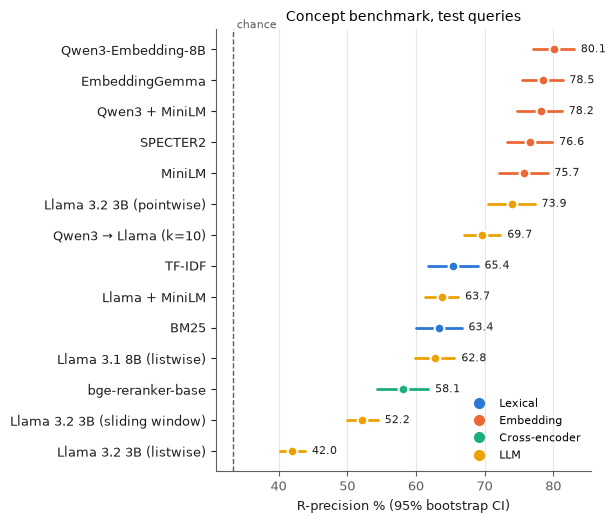

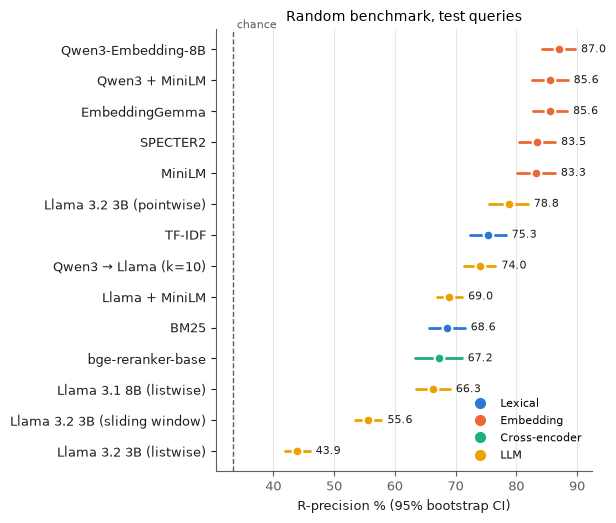

In [6]:
from src.figures import fig_bench_compare, fig_forest
for bench, t in tables.items():
    m = pd.concat([t["methods"], t["extra"]]).sort_values("rprec", ascending=False) if "extra" in t else t["methods"]
    save(fig_forest(m, bench), f"05_rprec_ci_{bench}")

**Figure (05_rprec_ci_<bench>).** Test-set R-precision per method, with 95% percentile-bootstrap CIs over queries; methods with several shuffle seeds are averaged per query first. Color marks the method family; the dashed line is the expected value of a random ranking.

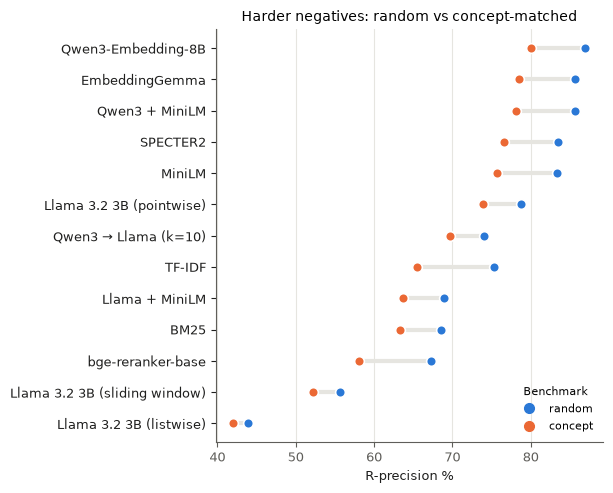

In [7]:
if {"random", "concept"} <= set(tables):
    save(fig_bench_compare(tables), "05_bench_compare")

**Figure (05_bench_compare).** The same methods on both benchmarks. The gap between the two points shows how much each method depends on negatives being topically unrelated.

### Findings

Test split, 118 queries. R-precision is the primary metric; MRR saturates (EmbeddingGemma scores 1.000 on `random`). Values are means with 95% bootstrap CIs and Holm-corrected Wilcoxon p-values. The order-sensitive LLM methods are averaged over 5 shuffle seeds.

- **Embedding models lead on both benchmarks.**
  - Qwen3-Embedding-8B is best: 87.0 [84.2, 89.7] on `random` and 80.1 [77.0, 83.0] on `concept`.
  - EmbeddingGemma, Qwen3 + MiniLM, SPECTER2 and MiniLM all sit within 4.5 points, with overlapping CIs.
  - Qwen3 beats MiniLM on R-precision (+3.7, p = 0.0048; +4.3, p = 0.0074) but not on MRR.
  - SPECTER2 and MiniLM are indistinguishable (Holm p ≥ 0.84).
  - A 22M-parameter model is therefore within 3.7 / 4.3 points of an 8B one.
- **Embeddings beat lexical matching clearly.** MiniLM vs TF-IDF: +8.0 on `random`, +10.3 on `concept` (p ≤ 9e-07). Qwen3 vs BM25: +18.4 / +16.7.
- **Listwise Llama is the weakest method by far.**
  - Full-list listwise scores 43.9 [41.9, 46.0] on `random` and 42.0 [40.2, 43.9] on `concept`, barely above chance (33.3) and about 40 points below Qwen3 (Holm p ≤ 3.4e-19).
  - The sliding window adds 10–12 points (p ≤ 2e-13), but stays below every non-LLM method, bge-reranker included (−11.6, p = 9e-07; −5.9, p = 0.0078).
- **Pointwise is the strongest LLM variant.** It scores 78.8 and 73.9: above TF-IDF and bge-reranker (+11.5, +15.8 vs bge; p ≤ 1.4e-05), and below all embedding models.
- **LLM reranking hurts the two-stage pipeline.** Qwen3 → Llama (k = 10) scores 74.0 and 69.7, which is 13.0 and 10.4 points **below** Qwen3 alone (p ≤ 3e-10), even though Qwen3's top 10 already holds about 90% of the true references (see `06_analysis`).
- **bge-reranker underperforms.** It scores 67.2 and 58.1, below both TF-IDF and BM25 on both benchmarks (BM25: 68.6 / 63.4). Its 512-token input limit truncates the query-candidate pairs.
- **Seeds do not change the picture.** Across 5 shuffle seeds, the standard deviation of mean R-precision is 0.8–2.0 points for every LLM method. Full-list Llama's best seed (46.3) is still below every other method's mean.